# Mandatory 2
Date: 9.11.2026
Dataset: QSAR Toxicity
Course: STK-IN4300  
Name: Esther Zijerveld

In [ ]:
# Import necessary libraries
%matplotlibinline
import pandas as pd
import numpy as np
import scipy
import sklearn

In [84]:
# Data comes from QSAR toxicity
data = pd.read_csv("data/qsar_aquatic_toxicity.csv", sep=";")
data.columns = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040", "LC50"]

In [85]:
data.head()

,TPSA,SAacc,H050,MLOGP,RDCHI,GATS1p,nN,C040,LC50
0,0.00,0.000,0,2.638,1.401,0.632,0,0,4.330
1,9.23,11.000,0,5.799,2.930,0.486,0,0,7.019
2,9.23,11.000,0,5.453,2.887,0.495,0,0,6.723
3,9.23,11.000,0,4.068,2.758,0.695,0,0,5.979
4,215.34,327.629,3,0.189,4.677,1.333,0,4,6.064


In [86]:
data.describe()

,TPSA,SAacc,H050,MLOGP,RDCHI,GATS1p,nN,C040,LC50
count,545.000000,545.000000,545.000000,545.000000,545.000000,545.00000,545.000000,545.000000,545.000000
mean,48.561872,58.977035,0.939450,2.313299,2.494624,1.04696,1.005505,0.354128,4.660106
std,46.760699,68.182392,1.619619,1.743392,0.809925,0.40372,1.397860,0.807426,1.666279
min,0.000000,0.000000,0.000000,-6.446000,1.000000,0.28100,0.000000,0.000000,0.122000
25%,15.790000,11.000000,0.000000,1.228000,1.975000,0.73700,0.000000,0.000000,3.601000
50%,40.460000,42.683000,0.000000,2.273000,2.344000,1.02100,1.000000,0.000000,4.530000
75%,70.140000,77.727000,1.000000,3.395000,2.913000,1.26700,2.000000,0.000000,5.610000
max,347.320000,571.952000,18.000000,9.148000,6.439000,2.50000,11.000000,11.000000,10.047000


In [87]:
X = data.loc[:, "TPSA" : "C040"]
y = data[:]["LC50"]
X["intercept"] = 1

X.head()

,TPSA,SAacc,H050,MLOGP,RDCHI,GATS1p,nN,C040,intercept
0,0.00,0.000,0,2.638,1.401,0.632,0,0,1
1,9.23,11.000,0,5.799,2.930,0.486,0,0,1
2,9.23,11.000,0,5.453,2.887,0.495,0,0,1
3,9.23,11.000,0,4.068,2.758,0.695,0,0,1
4,215.34,327.629,3,0.189,4.677,1.333,0,4,1


### (a) Fit linear regression models
split into training and test

(i) model count variables as a linear effect
(ii) transform using dummy encoding

In [88]:
X_binary = X.copy()
X_binary.iloc[:, [2, 6, 7]] = np.where(X_binary.iloc[:, [2, 6, 7]] > 0, 1, 0)
print(X_binary.head())

from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

X_train_bin, X_test_bin, y_train, y_test = train_test_split(
    X_binary, y, test_size=0.33, random_state=42)



     TPSA    SAacc  H050  MLOGP  RDCHI  GATS1p  nN  C040  intercept
0    0.00    0.000     0  2.638  1.401   0.632   0     0          1
1    9.23   11.000     0  5.799  2.930   0.486   0     0          1
2    9.23   11.000     0  5.453  2.887   0.495   0     0          1
3    9.23   11.000     0  4.068  2.758   0.695   0     0          1
4  215.34  327.629     1  0.189  4.677   1.333   0     1          1


Standardise the data

In [89]:
from sklearn.preprocessing import StandardScaler


std_scaler = StandardScaler()
X_train_sc = std_scaler.fit_transform(X_train)
X_test_sc = std_scaler.transform(X_test)
X_train_bin_sc = std_scaler.fit_transform(X_train_bin)
X_test_bin_sc = std_scaler.transform(X_test_bin)
X_train_sc = pd.DataFrame(X_train_sc)
X_test_sc = pd.DataFrame(X_test_sc)
X_train_bin_sc = pd.DataFrame(X_train_bin_sc)
X_test_bin_sc = pd.DataFrame(X_test_bin_sc)


#print(X_train_sc[:5][:])
#y_train_sc = std_scaler.fit_transform(y_train)
#y_test_sc = std_scaler.transform(y_test)

Fit two separate regression models

In [ ]:
from sklearn.linear_model import LinearRegression

# Initialising the linear regression
reg = LinearRegression()

# Fitting to the training data
reg.fit(X_train_sc, y_train)

print(reg.score(X_test_sc, y_test))

# Prediction on test set
y_pred = reg.predict(X_test)

# Calculating the RMSE
err = np.sqrt(1/len(y_pred)*np.sum((y_pred - y_test)**2))
print(err)

0.5035650972102842
39.07620711687484


c:\Users\esthe\OneDrive\Dokumenter\UiO\STK-IN4300\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [ ]:
reg = LinearRegression()

reg.fit(X_train_bin, y_train)
print(reg.score(X_test_bin, y_test))

y_pred = reg.predict(X_test_bin)

err = np.sqrt(1/len(y_pred)*np.sum((y_pred - y_test)**2))
print(err)

0.49479039276577796
1.3591156085173297


In [34]:
from scipy.stats import t as student_t
from sklearn.metrics import mean_squared_error

count_columns = ["H050", "nN", "C040"]

# Option (ii): encode count predictors as categorical indicators; use training levels only.
X_train_dummies = pd.get_dummies(
    X_train, columns=count_columns, drop_first=True, dtype=float
)
X_test_dummies = pd.get_dummies(
    X_test, columns=count_columns, drop_first=True, dtype=float
).reindex(columns=X_train_dummies.columns, fill_value=0.0)


def fit_ols_with_inference(X_fit, y_fit):
    """Fit OLS with standardized predictors and classical coefficient tests."""
    means = X_fit.mean(axis=0).to_numpy(dtype=float)
    scales = X_fit.std(axis=0, ddof=0).to_numpy(dtype=float)
    scales = np.where(scales == 0, 1.0, scales)

    Z_fit = (X_fit.to_numpy(dtype=float) - means) / scales
    design = np.ones((len(X_fit), 1))
    selected_indices = []
    for column_index in range(Z_fit.shape[1]):
        candidate = np.column_stack([design, Z_fit[:, column_index]])
        if np.linalg.matrix_rank(candidate) > np.linalg.matrix_rank(design):
            selected_indices.append(column_index)
            design = candidate

    y_values = y_fit.to_numpy(dtype=float)
    beta = np.linalg.lstsq(design, y_values, rcond=None)[0]
    residuals = y_values - design @ beta
    residual_df = len(y_values) - design.shape[1]
    residual_variance = residuals @ residuals / residual_df
    covariance = residual_variance * np.linalg.pinv(design.T @ design, hermitian=True)

    coefficients = np.full(X_fit.shape[1], np.nan)
    standard_errors = np.full(X_fit.shape[1], np.nan)
    p_values = np.full(X_fit.shape[1], np.nan)
    selected_scales = scales[selected_indices]
    coefficients[selected_indices] = beta[1:] / selected_scales
    standard_errors[selected_indices] = np.sqrt(np.diag(covariance)[1:]) / selected_scales
    t_statistics = beta[1:] / np.sqrt(np.diag(covariance)[1:])
    p_values[selected_indices] = 2 * student_t.sf(np.abs(t_statistics), df=residual_df)

    intercept_transform = np.r_[1.0, -means[selected_indices] / selected_scales]
    intercept = intercept_transform @ beta
    intercept_se = np.sqrt(intercept_transform @ covariance @ intercept_transform)
    coefficient_table = pd.DataFrame(
        {
            "coefficient": np.r_[intercept, coefficients],
            "std_error": np.r_[intercept_se, standard_errors],
            "p_value": np.r_[
                2 * student_t.sf(abs(intercept / intercept_se), df=residual_df),
                p_values,
            ],
        },
        index=["Intercept", *X_fit.columns],
    )
    coefficient_table["estimable"] = [True, *[index in selected_indices for index in range(X_fit.shape[1])]]
    coefficient_table["significant_at_0.05"] = coefficient_table["p_value"] < 0.05

    def predict(X_new):
        Z_new = (X_new.to_numpy(dtype=float) - means) / scales
        Z_new = Z_new[:, selected_indices]
        return beta[0] + Z_new @ beta[1:]

    return predict, coefficient_table


# Option (i): use every predictor as supplied, including linear count effects.
predict_linear, coefficients_linear = fit_ols_with_inference(X_train, y_train)

# Option (ii): use the same continuous predictors and dummy-coded count predictors.
predict_dummy, coefficients_dummy = fit_ols_with_inference(
    X_train_dummies, y_train
)

predictions = {
    "Linear count effects": (predict_linear(X_train), predict_linear(X_test)),
    "Dummy-coded counts": (
        predict_dummy(X_train_dummies),
        predict_dummy(X_test_dummies),
    ),
}

error_rows = []
for model_name, (train_prediction, test_prediction) in predictions.items():
    train_mse = mean_squared_error(y_train, train_prediction)
    test_mse = mean_squared_error(y_test, test_prediction)
    error_rows.append(
        {
            "model": model_name,
            "training_MSE": train_mse,
            "training_RMSE": np.sqrt(train_mse),
            "test_MSE": test_mse,
            "test_RMSE": np.sqrt(test_mse),
        }
    )

error_table = pd.DataFrame(error_rows).set_index("model")
print("Training and test errors (LC50 units for RMSE):")
display(error_table.round(4))

print("\nOption (i): coefficient estimates and two-sided t-tests")
display(coefficients_linear.sort_values("p_value").round(5))

print("\nOption (ii): coefficient estimates and two-sided t-tests")
display(coefficients_dummy.sort_values("p_value").round(5))

Training and test errors (LC50 units for RMSE):


,training_MSE,training_RMSE,test_MSE,test_RMSE
model,,,,
Linear count effects,1.4790,1.2161,1.3355,1.1556
Dummy-coded counts,1.3886,1.1784,1.3550,1.1641



Option (i): coefficient estimates and two-sided t-tests


,coefficient,std_error,p_value,estimable,significant_at_0.05
TPSA,0.02878,0.00343,0.00000,True,True
Intercept,2.64293,0.31904,0.00000,True,True
SAacc,-0.01560,0.00264,0.00000,True,True
MLOGP,0.46165,0.08023,0.00000,True,True
nN,-0.24153,0.05995,0.00007,True,True
RDCHI,0.50730,0.17150,0.00330,True,True
GATS1p,-0.50509,0.19991,0.01195,True,True
C040,0.03822,0.09227,0.67900,True,False
H050,0.02276,0.07922,0.77408,True,False



Option (ii): coefficient estimates and two-sided t-tests


,coefficient,std_error,p_value,estimable,significant_at_0.05
TPSA,0.02981,0.00359,0.00000,True,True
Intercept,2.52076,0.34251,0.00000,True,True
SAacc,-0.01722,0.00285,0.00000,True,True
MLOGP,0.49500,0.08649,0.00000,True,True
H050_8,-3.78082,1.34237,0.00514,True,True
nN_5,-1.21773,0.47569,0.01090,True,True
RDCHI,0.46493,0.18251,0.01130,True,True
GATS1p,-0.43836,0.20553,0.03366,True,True
nN_4,-0.97881,0.46801,0.03723,True,True
H050_7,2.21884,1.09070,0.04270,True,True


### Results and interpretation

The split contains 365 training and 180 test observations. In option (i), H050, nN, and C040 enter as linear count effects. In option (ii), each is dummy-encoded, with count 0 as the reference level. The reported p-values are two-sided classical OLS t-tests on the training data (alpha = 0.05; no multiple-testing adjustment).

For option (i), TPSA (positive), SAacc (negative), MLOGP (positive), RDCHI (positive), GATS1p (negative), and nN (negative) are significant. H050 and C040 are not significant. In option (ii), the five continuous predictors remain significant; among count-level contrasts, H050=7 and H050=8 have positive and negative estimates respectively, and nN=4 and nN=5 have negative estimates. The other estimable count-level coefficients are not significant. These contrasts are relative to count 0, conditional on the other predictors. The nN=7 and C040=11 terms are perfectly collinear in the training data, so their separate effects are not estimable and are marked accordingly in the coefficient table. Treat the isolated significant dummy contrasts cautiously, particularly given the number of tests.

| Count-variable model | Training MSE | Training RMSE | Test MSE | Test RMSE |
|---|---:|---:|---:|---:|
| Linear count effects | 1.4790 | 1.2161 | 1.3355 | 1.1556 |
| Dummy-coded counts | 1.3886 | 1.1784 | 1.3550 | 1.1641 |

The dummy-coded model fits the training set slightly better, but has slightly higher test error. The linear-count model therefore generalizes marginally better on this split (test RMSE 1.1556 versus 1.1641); the difference is small, so there is no meaningful prediction-error advantage for dummy encoding here. RMSE is in LC50 units. Test-only count levels have no training-based coefficient and are treated as the reference level for prediction.

### (b) Repeat 200 times with different splits

Mean test errors over 200 paired splits (RMSE is in LC50 units):


test_MSE                 test_RMSE                
                         mean     std  median      mean     std  median
model                                                                  
Dummy-coded counts     1.6354  0.2314  1.6351    1.2757  0.0899  1.2787
Linear count effects   1.4794  0.1711  1.4822    1.2143  0.0705  1.2175

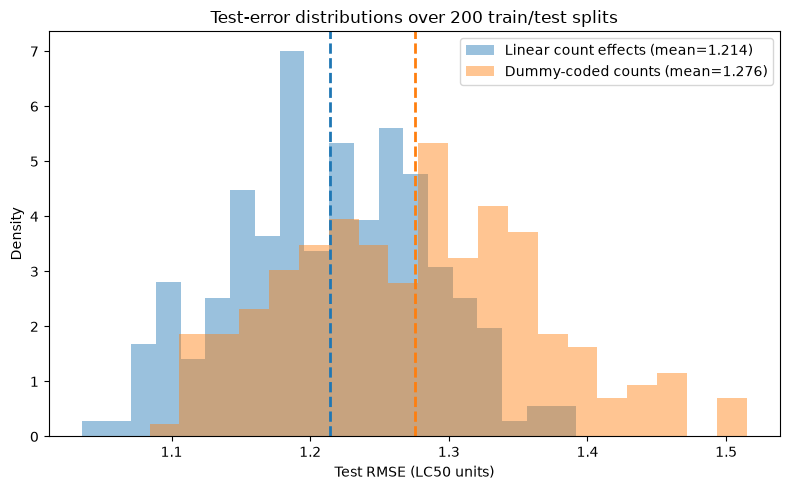

In [35]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

data = pd.read_csv("data/qsar_aquatic_toxicity.csv", sep=";")
data.columns = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040", "LC50"]
count_columns = ["H050", "nN", "C040"]

n_repeats = 200
repeated_errors = []
X_all = data.loc[:, "TPSA":"C040"]
y_all = data["LC50"]

for split_seed in range(n_repeats):
    X_train_rep, X_test_rep, y_train_rep, y_test_rep = train_test_split(
        X_all, y_all, test_size=0.33, random_state=split_seed
    )

    # Option (i): fit with the count variables as numeric linear effects.
    model_linear = LinearRegression().fit(X_train_rep, y_train_rep)
    pred_linear = model_linear.predict(X_test_rep)

    # Option (ii): dummy encode counts, learning levels from training data only.
    X_train_rep_dummy = pd.get_dummies(
        X_train_rep, columns=count_columns, drop_first=True, dtype=float
    )
    X_test_rep_dummy = pd.get_dummies(
        X_test_rep, columns=count_columns, drop_first=True, dtype=float
    ).reindex(columns=X_train_rep_dummy.columns, fill_value=0.0)
    model_dummy = LinearRegression().fit(X_train_rep_dummy, y_train_rep)
    pred_dummy = model_dummy.predict(X_test_rep_dummy)

    for model_name, prediction in [
        ("Linear count effects", pred_linear),
        ("Dummy-coded counts", pred_dummy),
    ]:
        mse = mean_squared_error(y_test_rep, prediction)
        repeated_errors.append(
            {
                "split": split_seed,
                "model": model_name,
                "test_MSE": mse,
                "test_RMSE": np.sqrt(mse),
            }
        )

repeated_errors = pd.DataFrame(repeated_errors)
repeated_error_summary = repeated_errors.groupby("model")[
    ["test_MSE", "test_RMSE"]
].agg(["mean", "std", "median"])
print("Mean test errors over 200 paired splits (RMSE is in LC50 units):")
display(repeated_error_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for model_name, color in [
    ("Linear count effects", "tab:blue"),
    ("Dummy-coded counts", "tab:orange"),
]:
    errors = repeated_errors.loc[
        repeated_errors["model"] == model_name, "test_RMSE"
    ]
    ax.hist(
        errors,
        bins=20,
        density=True,
        alpha=0.45,
        color=color,
        label=f"{model_name} (mean={errors.mean():.3f})",
    )
    ax.axvline(errors.mean(), color=color, linestyle="--", linewidth=2)

ax.set_xlabel("Test RMSE (LC50 units)")
ax.set_ylabel("Density")
ax.set_title("Test-error distributions over 200 train/test splits")
ax.legend()
fig.tight_layout()
plt.show()

### Results and interpretation

The 200 repetitions use the same test proportion and pair the two model comparisons on each split. The linear-count model has mean test MSE 1.4794 (SD 0.1711) and mean test RMSE 1.2143 (SD 0.0705). The dummy-coded model has mean test MSE 1.6354 (SD 0.2314) and mean test RMSE 1.2757 (SD 0.0899). Thus option (ii) has higher average error and more split-to-split variability in these repetitions. The figure shows the empirical distributions of test RMSE; the dashed lines mark each option's mean.

A single train/test split can give a noisy and split-dependent estimate of prediction performance: an unusually easy or difficult test set can change the ranking of the models. Repeating the split makes that variability visible and gives a more stable comparison of their expected test errors for this dataset and split procedure.

Option (ii) estimates separate effects for each observed count level, using many more parameters than the single linear count effect in option (i). This flexibility can lower training error, but estimates for uncommon count levels are based on few training examples and have high variance. Some levels may be absent from a training split altogether. If the count variables have a roughly ordered, smooth effect, dummy encoding also discards that structure and cannot share information across nearby count values. These effects can make dummy coding generalize worse despite its more flexible fit. The repeated splits show that the higher dummy-coded error is not specific to the single split in (a); they do not prove that option (ii) will always perform worse.

(C) Apply variable selection procedures (forward and backward selection) with different stopping criteria: AIC, BIC

$$AIC= -2\log(L) + 2k, \qquad BIC= -2\log(L) + k\log(n)$$

Here $L$ is the maximised likelihood, $k$ is the number of estimated parameters (including the intercept), and $n$ is the training sample size. Both criteria trade off fit and model complexity; BIC penalises extra parameters more strongly for this sample size.

Forward selection starts with an intercept-only model and adds the predictor that most decreases the chosen criterion, stopping when no addition improves it. Backward selection starts with all predictors and removes the predictor that most decreases the criterion, stopping when no removal improves it. Selection uses the training split only; the selected models are evaluated on the held-out test split.

On the 67/33 split from (a), forward and backward AIC both select TPSA, SAacc, MLOGP, RDCHI, GATS1p, and nN (test MSE 1.3341; RMSE 1.1550). Forward BIC selects MLOGP, TPSA, SAacc, and nN (test MSE 1.4128; RMSE 1.1886), while backward BIC selects the same six predictors as AIC (test MSE 1.3341; RMSE 1.1550). Forward BIC stops at a local solution: no single next addition improves BIC there, even though a different six-predictor model has a lower BIC. This illustrates that greedy forward/backward selection need not find the global optimum. All four selected models exclude H050 and C040.

In [43]:
def forward_selection(X, y):
    remaining = list(X.columns)
    selected = []

    # Start with intercept-only model
    current_X = sm.add_constant(X[selected])
    current_model = sm.OLS(y, current_X).fit()
    current_aic = current_model.aic

    while remaining:
        aic_values = {}

        # Try adding each remaining variable
        for variable in remaining:
            candidate = selected + [variable]
            candidate_X = sm.add_constant(X[candidate])

            model = sm.OLS(y, candidate_X).fit()
            aic_values[variable] = model.aic

        # Find variable giving lowest AIC
        best_variable = min(aic_values, key=aic_values.get)
        best_aic = aic_values[best_variable]

        # Stop if AIC does not decrease
        if best_aic >= current_aic:
            break

        selected.append(best_variable)
        remaining.remove(best_variable)

        current_aic = best_aic

        print(f"Added: {best_variable}, AIC: {current_aic:.3f}")

    # Fit final model
    final_X = sm.add_constant(X[selected])
    final_model = sm.OLS(y, final_X).fit()

    return final_model, selected

In [44]:
# Run forward selection
final_model, selected_variables = forward_selection(X_train, y_train)

# Display selected variables
print("\nSelected variables:")
print(selected_variables)

# Display final regression results
print(final_model.summary())

Added: MLOGP, AIC: 1297.791
Added: TPSA, AIC: 1246.478
Added: SAacc, AIC: 1212.647
Added: nN, AIC: 1201.909
Added: RDCHI, AIC: 1198.382
Added: GATS1p, AIC: 1192.875

Selected variables:
['MLOGP', 'TPSA', 'SAacc', 'nN', 'RDCHI', 'GATS1p']
                            OLS Regression Results                            
Dep. Variable:                   LC50   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     52.41
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           3.56e-46
Time:                        10:47:04   Log-Likelihood:                -589.44
No. Observations:                 365   AIC:                             1193.
Df Residuals:                     358   BIC:                             1220.
Df Model:                           6                                         
Covariance Type:            nonrobust              

In [45]:
def stepwise_selection(X, y, direction="forward", criterion="AIC"):

    remaining = list(X.columns)

    if direction == "forward":
        selected = []
    elif direction == "backward":
        selected = remaining.copy()
    else:
        raise ValueError("direction must be 'forward' or 'backward'")

    if criterion not in ["AIC", "BIC"]:
        raise ValueError("criterion must be 'AIC' or 'BIC'")

    def get_score(variables):
        X_model = sm.add_constant(X[variables])
        model = sm.OLS(y, X_model).fit()

        if criterion == "AIC":
            return model.aic
        else:
            return model.bic

    current_score = get_score(selected)

    while True:

        if direction == "forward":
            candidates = [
                v for v in remaining if v not in selected
            ]

            scores = {
                v: get_score(selected + [v])
                for v in candidates
            }

            if not scores:
                break

            best_variable = min(scores, key=scores.get)
            best_score = scores[best_variable]

            if best_score >= current_score:
                break

            selected.append(best_variable)

        else:  # backward selection

            candidates = selected.copy()

            scores = {
                v: get_score([x for x in selected if x != v])
                for v in candidates
            }

            if not scores:
                break

            best_variable = min(scores, key=scores.get)
            best_score = scores[best_variable]

            if best_score >= current_score:
                break

            selected.remove(best_variable)

        current_score = best_score

        print(
            f"{direction.capitalize()}: "
            f"{best_variable}, {criterion}: {current_score:.3f}"
        )

    final_model = sm.OLS(
        y, sm.add_constant(X[selected])
    ).fit()

    return final_model, selected

In [57]:
# Recreate the part (a) split; selection uses training data only.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42
)

selection_models = {}
selection_rows = []
for direction in ["forward", "backward"]:
    for criterion in ["AIC", "BIC"]:
        model, selected = stepwise_selection(
            X_train, y_train, direction=direction, criterion=criterion
        )
        test_design = sm.add_constant(X_test[selected], has_constant="add")
        test_prediction = model.predict(test_design)
        test_mse = mean_squared_error(y_test, test_prediction)
        selection_models[(direction, criterion)] = (model, selected)
        selection_rows.append(
            {
                "procedure": direction.capitalize(),
                "criterion": criterion,
                "selected_predictors": ", ".join(selected),
                "n_predictors": len(selected),
                "training_AIC": model.aic,
                "training_BIC": model.bic,
                "test_MSE": test_mse,
                "test_RMSE": np.sqrt(test_mse),
            }
        )

selection_summary = pd.DataFrame(selection_rows).set_index(
    ["procedure", "criterion"]
)
display(selection_summary.round(4))

Forward: MLOGP, AIC: 1297.791
Forward: TPSA, AIC: 1246.478
Forward: SAacc, AIC: 1212.647
Forward: nN, AIC: 1201.909
Forward: RDCHI, AIC: 1198.382
Forward: GATS1p, AIC: 1192.875
Forward: MLOGP, BIC: 1305.591
Forward: TPSA, BIC: 1258.177
Forward: SAacc, BIC: 1228.246
Forward: nN, BIC: 1221.409
Backward: H050, AIC: 1194.757
Backward: C040, AIC: 1192.875


ValueError: shapes (180,8) and (7,) not aligned: 8 (dim 1) != 7 (dim 0)

In [58]:
import pandas as pd

results = pd.DataFrame({
    "Method": ["Forward AIC", "Forward BIC",
               "Backward AIC", "Backward BIC"],
    "Number of variables": [
        len(vars_fwd_aic),
        len(vars_fwd_bic),
        len(vars_bwd_aic),
        len(vars_bwd_bic)
    ],
    "Selected variables": [
        vars_fwd_aic,
        vars_fwd_bic,
        vars_bwd_aic,
        vars_bwd_bic
    ],
    "AIC": [
        model_fwd_aic.aic,
        model_fwd_bic.aic,
        model_bwd_aic.aic,
        model_bwd_bic.aic
    ],
    "BIC": [
        model_fwd_aic.bic,
        model_fwd_bic.bic,
        model_bwd_aic.bic,
        model_bwd_bic.bic
    ]
})

print(results.to_string(index=False))

      Method  Number of variables                      Selected variables         AIC         BIC
 Forward AIC                    6 [MLOGP, TPSA, SAacc, nN, GATS1p, RDCHI] 1754.074649 1784.180149
 Forward BIC                    6 [MLOGP, TPSA, SAacc, nN, GATS1p, RDCHI] 1754.074649 1784.180149
Backward AIC                    6 [TPSA, SAacc, MLOGP, RDCHI, GATS1p, nN] 1754.074649 1784.180149
Backward BIC                    6 [TPSA, SAacc, MLOGP, RDCHI, GATS1p, nN] 1754.074649 1784.180149


In [38]:
import statsmodels.api as sm

regressor_OLS = sm.OLS(endog = y_train, exog = X_train_sc).fit()
regressor_OLS.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                   LC50   R-squared (uncentered):                   0.051
Model:                            OLS   Adj. R-squared (uncentered):              0.030
Method:                 Least Squares   F-statistic:                              2.402
Date:                Mon, 09 Nov 2026   Prob (F-statistic):                      0.0156
Time:                        10:34:06   Log-Likelihood:                         -1099.1
No. Observations:                 365   AIC:                                      2214.
Df Residuals:                     357   BIC:                                      2245.
Df Model:                           8                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1             1.3620      0.655      2.080      0.038       0.074       2.650
x2            -1.0722      0.732     -1.465      0.144      -2.512       0.367
x3             0.0343      0.482      0.071      0.943      -0.913       0.982
x4             0.7831      0.549      1.426      0.155      -0.297       1.863
x5             0.3965      0.541      0.733      0.464      -0.668       1.461
x6            -0.1956      0.312     -0.626      0.532      -0.810       0.419
x7            -0.3492      0.350     -0.998      0.319      -1.037       0.339
x8             0.0333      0.325      0.103      0.918      -0.606       0.672
==============================================================================
Omnibus:                       35.855   Durbin-Watson:                   0.134
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               46.710
Skew:                           0.726   Prob(JB):                     7.20e-11
Kurtosis:                       3.981   Cond. No.                         7.10
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [41]:
# Source - https://stackoverflow.com/a/46668898
# Posted by Varun-08, modified by community. See post 'Timeline' for change history
# Retrieved 2026-11-09, License - CC BY-SA 3.0

X_opt = X_train_sc[:,[0, 1, 3, 4, 5, 6, 7]]
regressor_OLS = sm.OLS(endog = y_train, exog = X_opt).fit()
regressor_OLS.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                   LC50   R-squared (uncentered):                   0.051
Model:                            OLS   Adj. R-squared (uncentered):              0.033
Method:                 Least Squares   F-statistic:                              2.752
Date:                Mon, 09 Nov 2026   Prob (F-statistic):                     0.00852
Time:                        10:36:57   Log-Likelihood:                         -1099.1
No. Observations:                 365   AIC:                                      2212.
Df Residuals:                     358   BIC:                                      2240.
Df Model:                           7                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1             1.3514      0.637      2.122      0.035       0.099       2.604
x2            -1.0414      0.590     -1.766      0.078      -2.201       0.118
x3             0.7710      0.522      1.478      0.140      -0.255       1.797
x4             0.3990      0.539      0.740      0.460      -0.661       1.459
x5            -0.2021      0.298     -0.677      0.499      -0.789       0.385
x6            -0.3432      0.339     -1.012      0.312      -1.010       0.323
x7             0.0258      0.307      0.084      0.933      -0.578       0.630
==============================================================================
Omnibus:                       35.493   Durbin-Watson:                   0.134
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               45.753
Skew:                           0.727   Prob(JB):                     1.16e-10
Kurtosis:                       3.947   Cond. No.                         5.65
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [42]:
X_opt = X_train_sc[:,[0, 1, 3, 4, 5, 6]]
regressor_OLS = sm.OLS(endog = y_train, exog = X_opt).fit()
regressor_OLS.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                   LC50   R-squared (uncentered):                   0.051
Model:                            OLS   Adj. R-squared (uncentered):              0.035
Method:                 Least Squares   F-statistic:                              3.219
Date:                Mon, 09 Nov 2026   Prob (F-statistic):                     0.00431
Time:                        10:37:31   Log-Likelihood:                         -1099.1
No. Observations:                 365   AIC:                                      2210.
Df Residuals:                     359   BIC:                                      2234.
Df Model:                           6                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1             1.3493      0.635      2.124      0.034       0.100       2.599
x2            -1.0342      0.583     -1.775      0.077      -2.180       0.112
x3             0.7672      0.519      1.478      0.140      -0.254       1.788
x4             0.4076      0.529      0.771      0.441      -0.632       1.447
x5            -0.2013      0.298     -0.676      0.500      -0.787       0.384
x6            -0.3418      0.338     -1.011      0.313      -1.007       0.323
==============================================================================
Omnibus:                       35.261   Durbin-Watson:                   0.134
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               45.356
Skew:                           0.724   Prob(JB):                     1.42e-10
Kurtosis:                       3.941   Cond. No.                         5.33
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## (d) Ridge regression
Use a bootstrap out-of-bag procedure and cross-validation to select the complexity parameter from a grid. Predictors are standardized within each fit; the response remains in its original units. The test split is reserved for final evaluation.


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# Candidate ridge penalty strengths; standardization is fitted within each training fold/sample.
lambdas = np.logspace(-4, 4, 41)

def ridge_model(alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))

In [ ]:
# Use the same 67/33 split as part (a), keeping the test set out of tuning.
X_ridge = data.loc[:, "TPSA":"C040"]
y_ridge = data["LC50"]
X_ridge_train, X_ridge_test, y_ridge_train, y_ridge_test = train_test_split(
    X_ridge, y_ridge, test_size=0.33, random_state=42
)

# Bootstrap estimate: evaluate each fit on the observations left out of its resample.
B = 300
n_train = len(y_ridge_train)
rng = np.random.default_rng(42)
bootstrap_mse = np.empty((len(lambdas), B))

for b in range(B):
    train_idx = rng.integers(0, n_train, size=n_train)
    in_bag = np.zeros(n_train, dtype=bool)
    in_bag[train_idx] = True
    oob_idx = np.flatnonzero(~in_bag)

    X_boot = X_ridge_train.iloc[train_idx].to_numpy(dtype=float)
    y_boot = y_ridge_train.iloc[train_idx].to_numpy(dtype=float)
    X_oob = X_ridge_train.iloc[oob_idx].to_numpy(dtype=float)
    y_oob = y_ridge_train.iloc[oob_idx].to_numpy(dtype=float)

    # Standardize within this resample, then solve the ridge path by eigendecomposition.
    x_mean = X_boot.mean(axis=0)
    x_scale = X_boot.std(axis=0)
    x_scale = np.where(x_scale == 0, 1.0, x_scale)
    Z_boot = (X_boot - x_mean) / x_scale
    Z_oob = (X_oob - x_mean) / x_scale
    y_mean = y_boot.mean()
    y_centered = y_boot - y_mean
    eigenvalues, eigenvectors = np.linalg.eigh(Z_boot.T @ Z_boot)
    projected_response = eigenvectors.T @ Z_boot.T @ y_centered

    for alpha_index, alpha in enumerate(lambdas):
        coefficients = eigenvectors @ (
            projected_response / (eigenvalues + alpha)
        )
        y_prediction = y_mean + Z_oob @ coefficients
        bootstrap_mse[alpha_index, b] = mean_squared_error(y_oob, y_prediction)

bootstrap_mean_mse = bootstrap_mse.mean(axis=1)
bootstrap_se_mse = bootstrap_mse.std(axis=1, ddof=1)
best_alpha_bootstrap = lambdas[np.argmin(bootstrap_mean_mse)]

# Five-fold CV on training data only; the pipeline standardizes inside each fold.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
ridge_cv = GridSearchCV(
    ridge_model(alpha=1.0),
    param_grid={"ridge__alpha": lambdas},
    scoring="neg_mean_squared_error",
    cv=cv,
    refit=True,
    n_jobs=1,
)
ridge_cv.fit(X_ridge_train, y_ridge_train)
cv_mean_mse = -ridge_cv.cv_results_["mean_test_score"]
cv_std_mse = ridge_cv.cv_results_["std_test_score"]
best_alpha_cv = ridge_cv.best_params_["ridge__alpha"]

# Evaluate the tuning choices once on the held-out test data.
ridge_bootstrap_final = ridge_model(best_alpha_bootstrap).fit(
    X_ridge_train, y_ridge_train
)
bootstrap_test_mse = mean_squared_error(
    y_ridge_test, ridge_bootstrap_final.predict(X_ridge_test)
)
cv_test_mse = mean_squared_error(
    y_ridge_test, ridge_cv.predict(X_ridge_test)
)

ridge_summary = pd.DataFrame(
    [
        {
            "tuning_method": "Bootstrap OOB",
            "best_alpha": best_alpha_bootstrap,
            "estimated_training_MSE": bootstrap_mean_mse.min(),
            "test_MSE": bootstrap_test_mse,
            "test_RMSE": np.sqrt(bootstrap_test_mse),
        },
        {
            "tuning_method": "5-fold CV",
            "best_alpha": best_alpha_cv,
            "estimated_training_MSE": cv_mean_mse.min(),
            "test_MSE": cv_test_mse,
            "test_RMSE": np.sqrt(cv_test_mse),
        },
    ]
).set_index("tuning_method")
display(ridge_summary.round(4))

# Plot estimated prediction error across the candidate alpha grid.
fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(lambdas, bootstrap_mean_mse, marker="o", ms=3, label="Bootstrap OOB MSE")
ax.semilogx(lambdas, cv_mean_mse, marker="s", ms=3, label="5-fold CV MSE")
ax.axvline(best_alpha_bootstrap, color="tab:blue", linestyle="--", alpha=0.8,
           label=f"Bootstrap choice: {best_alpha_bootstrap:.3g}")
ax.axvline(best_alpha_cv, color="tab:orange", linestyle=":", alpha=0.9,
           label=f"CV choice: {best_alpha_cv:.3g}")
ax.set_xlabel("Ridge complexity parameter (alpha)")
ax.set_ylabel("Estimated mean squared prediction error")
ax.set_title("Ridge tuning by bootstrap and cross-validation")
ax.legend()
fig.tight_layout()
plt.show()

### Tuning notes

The bootstrap resamples the training observations with replacement and estimates prediction error on the corresponding out-of-bag observations. Five-fold cross-validation uses shuffled folds. For both approaches, the standardization step is inside the ridge pipeline to prevent information from validation observations leaking into scaling. The grid-search selection uses only the training split; the held-out test errors are not used to select alpha. The two error curves can differ because bootstrap OOB fits typically use fewer distinct training observations than a five-fold CV fit. Ridge is fitted to all supplied predictors, with the three count variables treated as numeric linear effects, matching option (i) in part (a).

(e) Fit a Generalised Additive Model (GAM) in which the effects of variables are fitted using smoothing splines. Try two different levels of smoothing splines

AI declaration: Github copilot, chatgpt were used as aids.